# Détection de messages malveillants — classification binaire supervisée

## Version rigoureuse : validation croisée imbriquée

**Objectif.** Estimer avec moins de biais les performances d’une procédure qui choisit aussi ses hyperparamètres, puis entraîner et exporter un pipeline `Oui/Non` utilisable sur de nouvelles lignes.

> Le classeur est petit et indiqué comme pédagogique/synthétique. Les résultats décrivent ces données, pas la sécurité garantie de courriels réels.

## 1. Problématique et dictionnaire des variables

La cible est `message_malveillant` (`Non` ou `Oui`). Les entrées sont neuf mesures numériques; la date est réservée à l’exploration et exclue du modèle.

| Variable | Interprétation prudente |
|---|---|
| `date` | Date du message, EDA uniquement |
| `heure_envoi` | Heure d’envoi, 0–23 |
| `longueur_message` | Mesure fournie; unité non documentée |
| `nb_liens` | Nombre de liens, sans vérification de leur destination |
| `urgence_score` | Score d’urgence observé |
| `domaine_age_jours` | Âge du domaine; jeune peut être un indice, pas une preuve |
| `fautes_langue` | Nombre d’erreurs linguistiques |
| `expediteur_connu` | Indicateur binaire |
| `piece_jointe` | Indicateur binaire |
| `personnalisation_score` | Score observé |
| `message_malveillant` | Cible binaire Oui/Non |

Pas d’analyse du texte, de réputation de domaine, de lien ou de pièce jointe: les variables sont des signaux agrégés.

## 2. Importation et configuration

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (confusion_matrix, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, classification_report)

DATA_PATH = Path("dataset_phishing_ia.xlsx")
if not DATA_PATH.exists():
    DATA_PATH = Path("/home/ubuntu/deliverables/dataset_phishing_ia.xlsx")
OUT_DIR = DATA_PATH.resolve().parent
FEATURES = ["heure_envoi", "longueur_message", "nb_liens", "urgence_score",
            "domaine_age_jours", "fautes_langue", "expediteur_connu",
            "piece_jointe", "personnalisation_score"]
TARGET = "message_malveillant"
RANDOM_STATE = 42

## 3. Importation, qualité et statistiques descriptives

On conserve une copie brute pour compter les doublons, puis on retire les doublons exacts **avant** l’évaluation, ce qui évite qu’une copie identique se retrouve dans un pli d’entraînement et un pli d’évaluation. Les imputations et la standardisation, elles, restent dans le pipeline et sont donc ajustées uniquement sur les plis d’entraînement.

In [2]:
df_brut = pd.read_excel(DATA_PATH)
print("Dimensions brutes:", df_brut.shape)
print("Doublons exacts:", int(df_brut.duplicated().sum()))
df = df_brut.copy()
df[TARGET] = df[TARGET].astype(str).str.strip()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.drop_duplicates().reset_index(drop=True)
assert set(df[TARGET].dropna().unique()) <= {"Oui", "Non"}
X = df[FEATURES].copy()
y = (df[TARGET] == "Oui").astype(int)
print("Après déduplication:", df.shape)
print("Effectifs cible (Non=0, Oui=1):", y.map({0:"Non",1:"Oui"}).value_counts().to_dict())
display(df[FEATURES].describe().T.round(2))
display(df.isna().sum().rename("Valeurs manquantes").to_frame())

Dimensions brutes: (524, 11)
Doublons exacts: 4
Après déduplication: (520, 11)
Effectifs cible (Non=0, Oui=1): {'Non': 374, 'Oui': 146}


,count,mean,std,min,25%,50%,75%,max
heure_envoi,520.0,12.21,6.88,0.0,6.0,12.5,18.00,23.0
longueur_message,520.0,413.36,163.21,60.0,301.5,423.0,523.25,896.0
nb_liens,520.0,1.38,1.16,0.0,1.0,1.0,2.00,5.0
urgence_score,520.0,4.51,2.37,0.0,3.0,4.0,6.00,10.0
domaine_age_jours,510.0,740.68,764.34,1.0,217.0,512.5,962.50,5874.0
fautes_langue,520.0,2.02,1.39,0.0,1.0,2.0,3.00,6.0
expediteur_connu,520.0,0.44,0.50,0.0,0.0,0.0,1.00,1.0
piece_jointe,520.0,0.23,0.42,0.0,0.0,0.0,0.00,1.0
personnalisation_score,520.0,4.98,2.55,0.0,3.0,5.0,7.00,10.0


,Valeurs manquantes
date,0
heure_envoi,0
longueur_message,0
nb_liens,0
urgence_score,0
domaine_age_jours,10
fautes_langue,0
expediteur_connu,0
piece_jointe,0
personnalisation_score,0


## 4. EDA — distribution et corrélations

Ces graphiques décrivent l’échantillon. Les associations ne démontrent pas de causalité, et une distribution visible ne fournit pas une règle de sécurité.

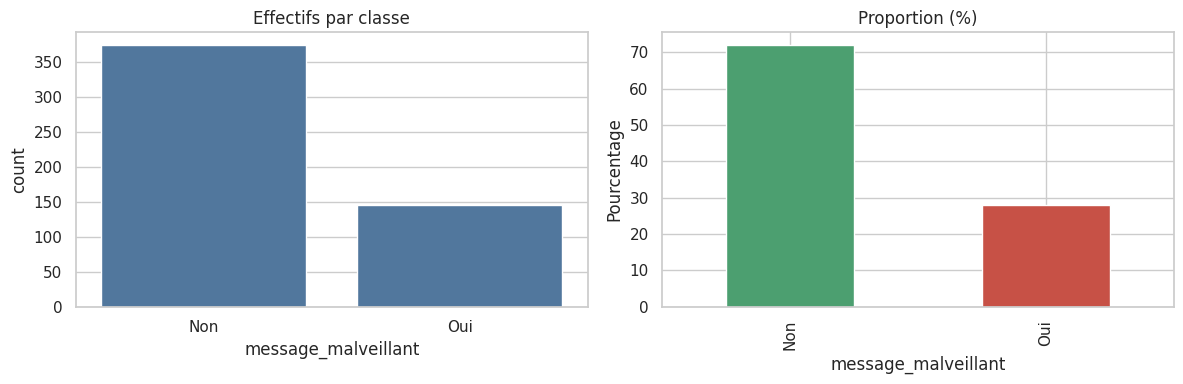

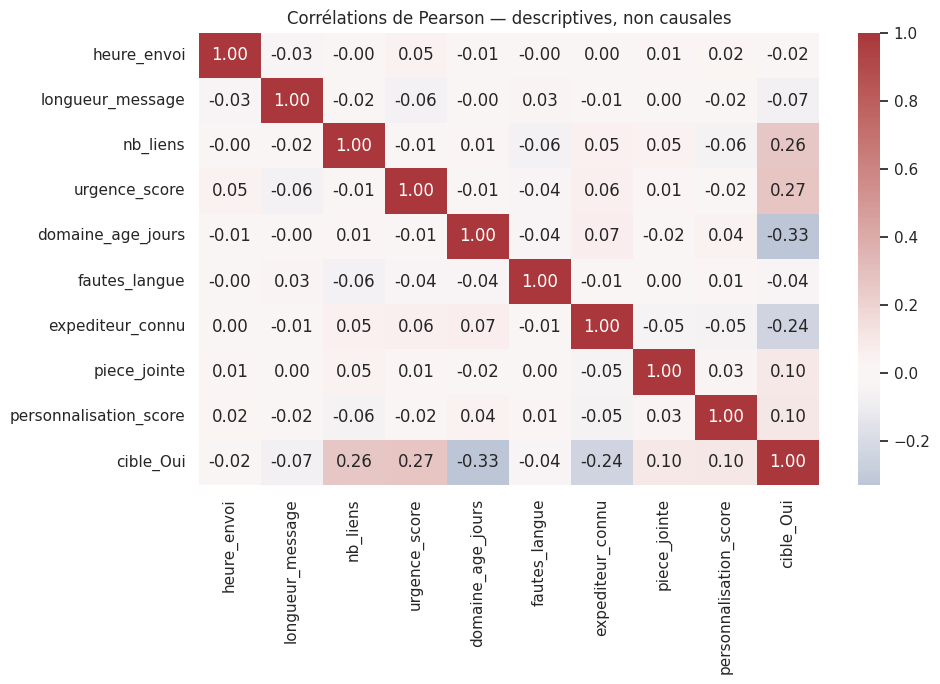

In [3]:
sns.set_theme(style="whitegrid")
# Effectifs et proportions de la cible sont déjà donnés à la cellule précédente : on évite le doublon.
corr = X.copy(); corr["cible_Oui"] = y
plt.figure(figsize=(10, 7))
sns.heatmap(corr.corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Corrélations de Pearson — descriptives, non causales")
plt.tight_layout(); plt.show()

## 5. Pourquoi une validation croisée imbriquée ?

Une validation simple peut donner une estimation instable sur seulement 520 observations. Si l’on choisit les hyperparamètres sur les mêmes plis que ceux utilisés pour annoncer le score, l’estimation peut être optimiste. La validation **imbriquée** sépare ces rôles:

- **Boucle externe stratifiée à 5 plis**: estime la généralisation. Chaque ligne est prédite une seule fois alors qu’elle est absente de l’entraînement de ce pli (prédiction hors pli, OOF).
- **Boucle interne stratifiée à 3 plis**: sélectionne les hyperparamètres en maximisant le **F1 macro** sur la partie apprentissage externe.
- Tous les traitements dépendants des données (imputation médiane, standardisation, modèle) sont dans le pipeline, donc appris seulement sur les sous-ensembles d’entraînement.

### F1 macro, ROC-AUC et logique d’évaluation

**F1 macro** est la moyenne simple des F1 de `Non` et `Oui`; chaque classe pèse autant malgré le déséquilibre. Un F1 combine précision et rappel; il diminue si l’un des deux est faible. Il sert ici au réglage pour éviter de se focaliser uniquement sur la classe majoritaire.

**ROC-AUC** mesure la capacité des scores à classer un exemple positif au-dessus d’un négatif à travers plusieurs seuils (0,5 ≈ hasard; 1 = séparation parfaite). Ce n’est pas le choix d’un seuil et cela ne remplace pas les décisions `predict()`. Pour le formulaire, la sortie reste binaire, sans réglage de seuil par l’utilisateur.

On publie aussi précision, rappel, F1 de la classe Oui, balanced accuracy et matrice de confusion. MAE/MSE/RMSE/R² sont conçues pour des erreurs de valeurs continues en régression; elles ne sont pas les métriques principales de ce problème de classification.

### Qu'est-ce que OOF (hors pli) ?

**OOF** = *Out-Of-Fold* : « hors pli ». On entraîne 5 modèles ; chacun prédit seulement les lignes qu'il n'a jamais vues. On obtient **une prédiction par ligne**, regroupées dans `predictions_nested_oof.csv`. La matrice OOF porte donc sur 520 observations, pas sur 104 : elle est plus stable qu'un test unique de 104 messages.

La validation est **imbriquée** : la boucle externe (5 plis) donne ces prédictions OOF pour estimer la performance ; la boucle interne (3 plis) choisit les hyperparamètres uniquement sur la partie entraînement de chaque pli externe. Le modèle livré est ensuite ré-entraîné sur les 520 lignes pour les nouvelles saisies : il ne produit donc pas les métriques OOF affichées.

TN = vrais négatifs (Non bien classés), FP = faux positifs (Non signalés à tort), FN = faux négatifs (malveillants manqués), TP = vrais positifs (malveillants détectés). On cherche à **augmenter TP** ; obtenir `FN = 0` et `FP = 0` en même temps exigerait une séparation parfaite, impossible ici (ROC-AUC ≈ 0,88).

La classe du formulaire vient directement de `predict()` : **aucun seuil manuel**. La probabilité affichée est une information complémentaire, pas une preuve et pas une décision automatique.

## 6. Modèles candidats et grilles

La logistique est un classificateur régularisé et relativement interprétable. Le SVM RBF compare une frontière non linéaire. Forêt aléatoire et Extra Trees testent des ensembles d’arbres. Les poids de classes sont réglés dans la boucle interne plutôt que d’être fixés après observation du test. Les grilles restent limitées compte tenu de la taille du jeu.

In [4]:
preprocessing = [
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
]
models = {
    "Régression logistique": (
        Pipeline(preprocessing + [("model", LogisticRegression(max_iter=2500, random_state=RANDOM_STATE))]),
        {"model__C": [0.03, 0.1, 0.3, 1, 3, 10],
         "model__class_weight": [None, "balanced", {0:1,1:1.5}, {0:1,1:2}, {0:1,1:3}]}
    ),
    "SVM RBF": (
        Pipeline(preprocessing + [("model", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))]),
        {"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced", {0:1,1:2}]}
    ),
    "Forêt aléatoire": (
        Pipeline(preprocessing + [("model", RandomForestClassifier(n_estimators=180, random_state=RANDOM_STATE, n_jobs=1))]),
        {"model__max_depth": [None, 6], "model__min_samples_leaf": [2,5],
         "model__class_weight": ["balanced", {0:1,1:2}]}
    ),
    "Extra Trees": (
        Pipeline(preprocessing + [("model", ExtraTreesClassifier(n_estimators=180, random_state=RANDOM_STATE, n_jobs=1))]),
        {"model__max_depth": [None, 6], "model__min_samples_leaf": [2,5],
         "model__class_weight": ["balanced", {0:1,1:2}]}
    ),
}
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=314)
print("Modèles:", list(models))

Modèles: ['Régression logistique', 'SVM RBF', 'Forêt aléatoire', 'Extra Trees']


## 7. Exécuter la validation imbriquée

Les scores affichés dans le tableau sont calculés séparément sur chacun des 5 plis externes, puis résumés par moyenne et écart-type (écart-type d’échantillon). Les prédictions OOF agrégées permettent également de construire une matrice de confusion où chaque observation apparaît une fois.

In [5]:
nested = {}
summary_rows = []
for name, (pipeline, param_grid) in models.items():
    oof_pred = np.zeros(len(y), dtype=int)
    oof_score = np.zeros(len(y), dtype=float)
    fold_rows = []
    chosen_params = []
    for fold, (train_idx, valid_idx) in enumerate(outer_cv.split(X, y), start=1):
        search = GridSearchCV(pipeline, param_grid, scoring="f1_macro", cv=inner_cv,
                              n_jobs=-1, refit=True, error_score="raise")
        search.fit(X.iloc[train_idx], y.iloc[train_idx])
        fitted = search.best_estimator_
        pred = fitted.predict(X.iloc[valid_idx])
        score = fitted.predict_proba(X.iloc[valid_idx])[:, list(fitted.classes_).index(1)]
        oof_pred[valid_idx] = pred
        oof_score[valid_idx] = score
        yt = y.iloc[valid_idx]
        fold_rows.append({
            "fold": fold,
            "f1_macro": f1_score(yt, pred, average="macro"),
            "f1_oui": f1_score(yt, pred, zero_division=0),
            "recall_oui": recall_score(yt, pred, zero_division=0),
            "precision_oui": precision_score(yt, pred, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(yt, pred),
            "roc_auc": roc_auc_score(yt, score),
        })
        chosen_params.append(search.best_params_)
    fold_df = pd.DataFrame(fold_rows)
    row = {"model": name}
    for metric in ["f1_macro", "f1_oui", "recall_oui", "precision_oui", "balanced_accuracy", "roc_auc"]:
        row[f"{metric}_mean"] = fold_df[metric].mean()
        row[f"{metric}_std"] = fold_df[metric].std(ddof=1)
    summary_rows.append(row)
    nested[name] = {"pred": oof_pred, "score": oof_score, "fold_metrics": fold_df, "params": chosen_params}
    print(f"{name}: F1 macro externe = {fold_df.f1_macro.mean():.3f} ± {fold_df.f1_macro.std(ddof=1):.3f}")

comparison = pd.DataFrame(summary_rows).sort_values("f1_macro_mean", ascending=False).reset_index(drop=True)
display(comparison.round(3))
comparison.to_csv(OUT_DIR / "comparaison_nested_cv.csv", index=False)
winner = comparison.iloc[0]["model"]
print("Modèle sélectionné par la moyenne F1 macro externe:", winner)

Régression logistique: F1 macro externe = 0.795 ± 0.043
SVM RBF: F1 macro externe = 0.794 ± 0.065
Forêt aléatoire: F1 macro externe = 0.766 ± 0.062
Extra Trees: F1 macro externe = 0.744 ± 0.047


,model,f1_macro_mean,f1_macro_std,f1_oui_mean,f1_oui_std,recall_oui_mean,recall_oui_std,precision_oui_mean,precision_oui_std,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std
0,Régression logistique,0.795,0.043,0.715,0.054,0.767,0.055,0.674,0.082,0.809,0.037,0.891,0.026
1,SVM RBF,0.794,0.065,0.719,0.086,0.794,0.095,0.664,0.112,0.814,0.059,0.892,0.033
2,Forêt aléatoire,0.766,0.062,0.657,0.097,0.636,0.149,0.699,0.093,0.762,0.068,0.882,0.034
3,Extra Trees,0.744,0.047,0.623,0.081,0.595,0.130,0.668,0.057,0.739,0.053,0.874,0.033


Modèle sélectionné par la moyenne F1 macro externe: Régression logistique


## 8. Matrice de confusion et erreurs OOF du modèle retenu

Ordre de la matrice: lignes = réel (`Non`, `Oui`), colonnes = prédit (`Non`, `Oui`). Un FN est un message Oui manqué; un FP est un message Non signalé à tort. **TP est une détection correcte, pas une erreur: on cherche à l’augmenter.** Avec ces données, FN=0 et FP=0 simultanément ne sont pas garantissables.

Matrice [[TN, FP], [FN, TP]]: [[318  56]
 [ 34 112]]
TN=318, FP=56, FN=34, TP=112
              precision    recall  f1-score   support

         Non       0.90      0.85      0.88       374
         Oui       0.67      0.77      0.71       146

    accuracy                           0.83       520
   macro avg       0.79      0.81      0.79       520
weighted avg       0.84      0.83      0.83       520

Accuracy agrégée: 0.8269230769230769
Balanced accuracy agrégée: 0.8086953336751885
Précision Oui agrégée: 0.6666666666666666
Rappel Oui agrégé: 0.7671232876712328
F1 Oui agrégé: 0.7133757961783439
F1 macro agrégé: 0.7947044270147918
ROC-AUC OOF agrégée (scores de plis combinés): 0.883396820745733


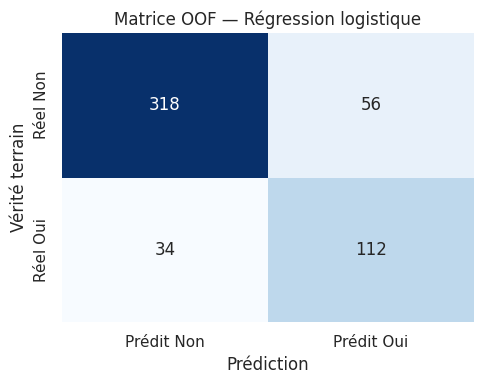

In [6]:
chosen = nested[winner]
yhat = chosen["pred"]
score = chosen["score"]
cm = confusion_matrix(y, yhat, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
print("Matrice [[TN, FP], [FN, TP]]:", cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(classification_report(y, yhat, target_names=["Non", "Oui"], zero_division=0))
print("Accuracy agrégée:", accuracy_score(y, yhat))
print("Balanced accuracy agrégée:", balanced_accuracy_score(y, yhat))
print("Précision Oui agrégée:", precision_score(y, yhat, zero_division=0))
print("Rappel Oui agrégé:", recall_score(y, yhat, zero_division=0))
print("F1 Oui agrégé:", f1_score(y, yhat, zero_division=0))
print("F1 macro agrégé:", f1_score(y, yhat, average="macro"))
print("ROC-AUC OOF agrégée (scores de plis combinés):", roc_auc_score(y, score))
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Prédit Non", "Prédit Oui"], yticklabels=["Réel Non", "Réel Oui"], ax=ax)
ax.set_xlabel("Prédiction"); ax.set_ylabel("Vérité terrain"); ax.set_title(f"Matrice OOF — {winner}")
plt.tight_layout(); plt.show()

## 9. Comparaison visuelle réel / prédit hors pli

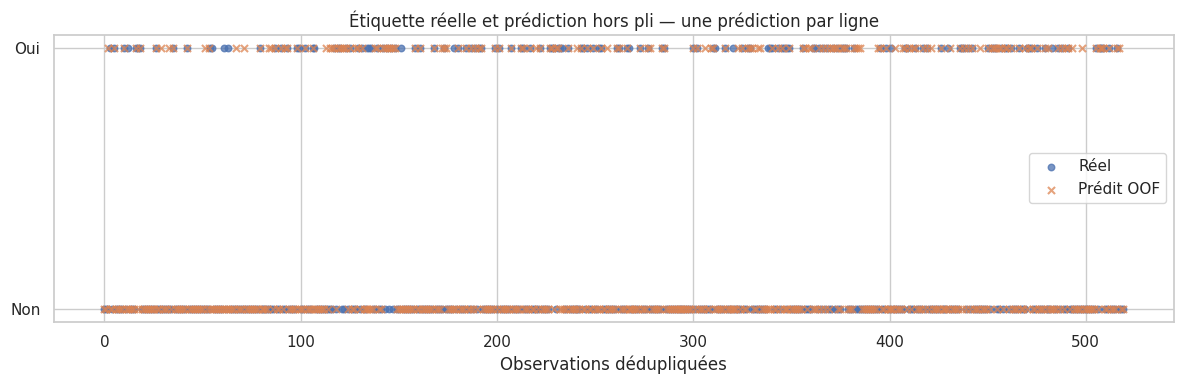

,real,prediction,probabilite_malveillant
0,Non,Non,0.033283
1,Non,Non,0.486823
2,Non,Oui,0.579559
3,Oui,Non,0.269960
4,Non,Non,0.158348
5,Oui,Oui,0.681781
6,Non,Non,0.146293
7,Non,Non,0.063240
8,Non,Non,0.208991
9,Non,Non,0.297762


In [7]:
oof_predictions = pd.DataFrame({
    "real": np.where(y == 1, "Oui", "Non"),
    "prediction": np.where(yhat == 1, "Oui", "Non"),
    "probabilite_malveillant": score,
})
oof_predictions.to_csv(OUT_DIR / "predictions_nested_oof.csv", index=False)
fig, ax = plt.subplots(figsize=(12,4))
pos = np.arange(len(y))
ax.scatter(pos, y, label="Réel", s=22, alpha=.75)
ax.scatter(pos, yhat, label="Prédit OOF", marker="x", s=26, alpha=.75)
ax.set_yticks([0,1], ["Non", "Oui"]); ax.set_xlabel("Observations dédupliquées")
ax.set_title("Étiquette réelle et prédiction hors pli — une prédiction par ligne")
ax.legend(); plt.tight_layout(); plt.show()
display(oof_predictions.head(10))

## 10. Modèle final et export Joblib

L’évaluation honnête ci-dessus provient des plis externes. Pour l’usage futur, on relance une recherche interne stratifiée à 5 plis sur toutes les données, puis `GridSearchCV(refit=True)` ajuste le meilleur pipeline sur l’ensemble des 520 lignes. Ce modèle final n’est **pas** évalué sur un nouveau test indépendant; les estimations de performance restent celles des plis externes.

In [8]:
final_pipeline, final_grid = models[winner]
final_search = GridSearchCV(final_pipeline, final_grid, scoring="f1_macro",
                            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                            n_jobs=-1, refit=True, error_score="raise")
final_search.fit(X, y)
artifact = {
    "pipeline": final_search.best_estimator_,
    "features": FEATURES,
    "target": TARGET,
    "mapping_cible": {0: "Non", 1: "Oui"},
    "selected_model": winner,
    "best_params": final_search.best_params_,
    "scoring": "F1 macro; CV imbriquée stratifiée 5 plis externes x 3 plis internes; refit final sur toutes les lignes",
    "random_state": RANDOM_STATE,
}
model_path = OUT_DIR / "modele_phishing_pipeline_tuned.joblib"
joblib.dump(artifact, model_path)
print("Modèle final:", winner)
print("Meilleurs paramètres sur toutes les données:", final_search.best_params_)
print("Meilleur F1 macro moyen de recherche finale:", final_search.best_score_)
print("Artefact exporté:", model_path)

Modèle final: Régression logistique
Meilleurs paramètres sur toutes les données: {'model__C': 10, 'model__class_weight': {0: 1, 1: 1.5}}
Meilleur F1 macro moyen de recherche finale: 0.8045589696330813
Artefact exporté: /home/himawari/Desktop/learn_python/iscae/Mini-projet 3: Veille stratégique – IA et confiance numérique/app_phishing_ia/work/modele_phishing_pipeline_tuned.joblib


## 11. Exemple de prédiction binaire sans seuil manuel

In [9]:
exemple = pd.DataFrame([{
    "heure_envoi": 22, "longueur_message": 350, "nb_liens": 3,
    "urgence_score": 8, "domaine_age_jours": 30, "fautes_langue": 3,
    "expediteur_connu": 0, "piece_jointe": 1, "personnalisation_score": 2,
}], columns=FEATURES)
prediction = int(artifact["pipeline"].predict(exemple)[0])
probabilite_oui = float(artifact["pipeline"].predict_proba(exemple)[0, list(artifact["pipeline"].classes_).index(1)])
print("Prédiction binaire:", {0:"Non",1:"Oui"}[prediction])
print(f"Probabilité estimée Oui (information complémentaire): {probabilite_oui:.1%}")
print("Aucun seuil personnalisé: la classe provient directement de predict().")

Prédiction binaire: Oui
Probabilité estimée Oui (information complémentaire): 98.0%
Aucun seuil personnalisé: la classe provient directement de predict().


## 12. Conclusion et limites

La recherche imbriquée limite le biais dû au réglage des hyperparamètres, mais elle ne rend pas un petit jeu synthétique représentatif du monde réel. Les plis donnent ici une matrice OOF agrégée avec des faux négatifs et des faux positifs non nuls. Aucun résultat ne permet de promettre zéro erreur. Le classificateur est une aide pédagogique; une validation externe sur des données réelles représentatives est nécessaire avant tout usage de sécurité.

Fichiers créés dans le dossier du classeur: `comparaison_nested_cv.csv`, `predictions_nested_oof.csv` et `modele_phishing_pipeline_tuned.joblib`.